In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import os
import glob
import pyblock
import scipy.stats

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "Times New Roman",
    "font.serif": ["Arial"],  # or other preferred serif font
    "mathtext.fontset": "cm",            # Computer Modern for math text
    "text.usetex": False,                 # Use LaTeX for text rendering]
    "pdf.fonttype": 42,                 # Use LaTeX for text rendering

    # Figure
    "figure.figsize": (6, 4),            # width, height in inches
    "figure.dpi": 100,                   # high resolution

    # Axes
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.linewidth": 1.2,
    "axes.grid": True,                   # optional, remove if you want no grid
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

aa3_to_aa1 = {
    "Ala": "A",
    "Arg": "R",
    "Asn": "N",
    "Asp": "D",
    "Cys": "C",
    "Gln": "Q",
    "Glu": "E",
    "Gly": "G",
    "His": "H",
    "Ile": "I",
    "Leu": "L",
    "Lys": "K",
    "Met": "M",
    "Phe": "F",
    "Pro": "P",
    "Ser": "S",
    "Thr": "T",
    "Trp": "W",
    "Tyr": "Y",
    "Val": "V",
    "Pro_cis": "Pc"
}

def RMSE(pred, true):
    return np.sqrt(np.mean((pred - true) ** 2))


tripeptides = ['Ala','Arg','Asn','Asp','Cys','Gln','Glu','Gly','His','Ile','Leu','Lys','Met','Phe','Ser','Thr','Trp','Tyr','Val']


In [12]:

base_path = "../AXA_peptides/"

df = pd.DataFrame()
df['AA'] = tripeptides

pop_open_M9 = []
pop_open_M10 = []
pop_open_M9_err = []
pop_open_M10_err = []
rg = []
rg_err = []
code = []

for aa in tripeptides:
    code.append(aa3_to_aa1[aa])
    filepath_M9 = os.path.join(base_path, aa, "SIM", "M9", "fopen.npy")
    filepath_M10 = os.path.join(base_path, aa, "SIM", "M10", "fopen.npy")
    filepath_rg = os.path.join(base_path, aa, "SIM", "BB_rg_data", "rg_traj_fit.txt")

    if not os.path.isfile(filepath_M9):
        print(f"Skipping {aa}: M9 file not found.")
        continue

    fopenM9 = np.load(filepath_M9)[:,1] # only middle residue
    fopenM10 = np.load(filepath_M10)[:,1] # only middle residue
    rg_data = np.loadtxt(filepath_rg) 

    pop_open_M9.append(np.mean(fopenM9))
    pop_open_M10.append(np.mean(fopenM10))
    rg.append(np.mean(rg_data))

    # errors M9 
    reblock_data = pyblock.blocking.reblock(fopenM9)
    opt = pyblock.blocking.find_optimal_block(len(fopenM9), reblock_data)[0]
    err_fopen_M9 = reblock_data[opt][4]

    # errors M10
    reblock_data = pyblock.blocking.reblock(fopenM10)
    opt = pyblock.blocking.find_optimal_block(len(fopenM10), reblock_data)[0]
    err_fopen_M10 = reblock_data[opt][4]

    # errors rg
    reblock_data = pyblock.blocking.reblock(rg_data)
    opt = pyblock.blocking.find_optimal_block(len(rg_data), reblock_data)[0]
    err_rg = reblock_data[opt][4]

    # append errors
    pop_open_M9_err.append(err_fopen_M9)
    pop_open_M10_err.append(err_fopen_M10)
    rg_err.append(err_rg)
       

df['p_open_M9'] = np.round(pop_open_M9, 4)
df['p_open_M9 ±'] = np.round(pop_open_M9_err, 4)
df['p_open_M10'] = np.round(pop_open_M10, 4)
df['p_open_M10 ±'] = np.round(pop_open_M10_err, 4)
df['rg'] = np.round(rg, 4)
df['rg ±'] = np.round(rg_err, 4)
df['aa'] = code

# calculate protection factors
df["PF_M9"] = np.round(1 / df['p_open_M9'], 4)
df["PF_M10"] = np.round(1 / df['p_open_M10'], 4)
df["PF_M9 ±"] = np.round(df['p_open_M9 ±'] / (df['p_open_M9'] ** 2), 4)
df["PF_M10 ±"] = np.round(df['p_open_M10 ±'] / (df['p_open_M10'] ** 2), 4)

# save
df.to_csv(f'AXA_tripeptides_M9_M10_PF_rg.csv', index=False)








In [13]:
df

,AA,p_open_M9,p_open_M9 ±,p_open_M10,p_open_M10 ±,rg,rg ±,aa,PF_M9,PF_M10,PF_M9 ±,PF_M10 ±
0,Ala,0.8581,0.0087,0.9772,0.0012,0.3600,0.0011,A,1.1654,1.0233,0.0118,0.0013
1,Arg,0.7478,0.0131,0.9617,0.0022,0.3588,0.0033,R,1.3373,1.0398,0.0234,0.0024
2,Asn,0.6764,0.0122,0.9369,0.0032,0.3567,0.0012,N,1.4784,1.0673,0.0267,0.0036
3,Asp,0.4132,0.0279,0.8834,0.0075,0.3465,0.0026,D,2.4201,1.1320,0.1634,0.0096
4,Cys,0.6192,0.0109,0.9377,0.0031,0.3583,0.0012,C,1.6150,1.0664,0.0284,0.0035
5,Gln,0.7014,0.0133,0.9391,0.0046,0.3604,0.0018,Q,1.4257,1.0648,0.0270,0.0052
6,Glu,0.7035,0.0149,0.9526,0.0028,0.3555,0.0019,E,1.4215,1.0498,0.0301,0.0031
7,Gly,0.8564,0.0049,0.9671,0.0013,0.3495,0.0008,G,1.1677,1.0340,0.0067,0.0014
8,His,0.5203,0.0227,0.8013,0.0143,0.3487,0.0022,H,1.9220,1.2480,0.0839,0.0223
9,Ile,0.5120,0.0215,0.9046,0.0070,0.3592,0.0016,I,1.9531,1.1055,0.0820,0.0086


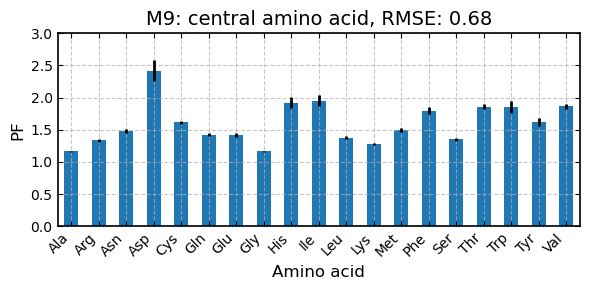

In [7]:
# plot PFs M9 and add RMSE to title

df.plot(x='AA', y='PF_M9', yerr='PF_M9 ±', kind='bar', figsize=(6, 3), legend=False)
plt.xlabel('Amino acid')
plt.ylabel('PF')
plt.xticks(rotation=45, ha='right')  
plt.title('M9: central amino acid, RMSE: {:.2f}'.format(np.round(RMSE(df['PF_M9'], np.ones(len(df))), 4)))
plt.ylim(0,3)
plt.tight_layout()
plt.savefig('PF_M9.png')

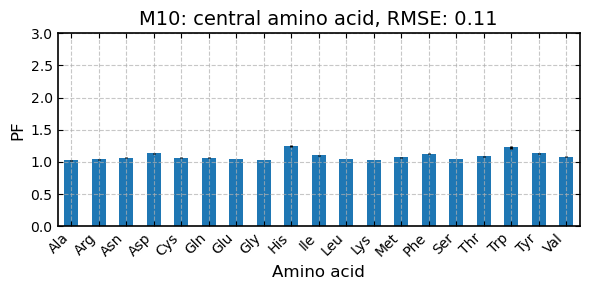

In [8]:
# plot PFs M10 and add RMSE to title

df.plot(x='AA', y='PF_M10', yerr='PF_M10 ±', kind='bar', figsize=(6, 3), legend=False)
plt.xlabel('Amino acid')
plt.ylabel('PF')
plt.xticks(rotation=45, ha='right')  
plt.title('M10: central amino acid, RMSE: {:.2f}'.format(np.round(RMSE(df['PF_M10'], np.ones(len(df))), 4)))
plt.ylim(0,3)
plt.tight_layout()
plt.savefig('PF_M10.png')

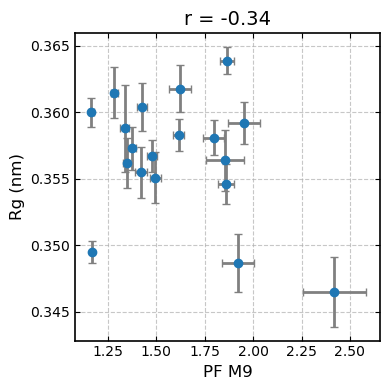

In [15]:
# correlation between PF M9 and rg

plt.figure(figsize=(4, 4))
plt.errorbar(x=df['PF_M9'], y=df['rg'], xerr=df['PF_M9 ±'], yerr=df['rg ±'], fmt='o', ecolor='gray', capsize=3)
plt.xlabel('PF M9')
plt.ylabel('Rg (nm)')
plt.title('r = {:.2f}'.format(scipy.stats.pearsonr(df['PF_M9'], df['rg'])[0]))
plt.tight_layout()
plt.savefig('PF_M9_rg_correlation.png')


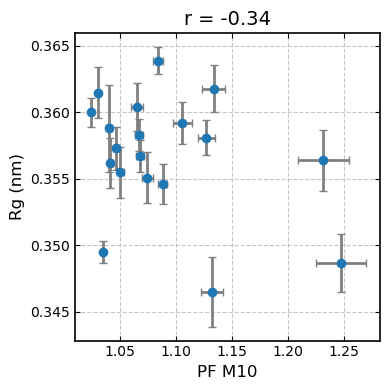

In [16]:
# correlation between PF M10 and rg

plt.figure(figsize=(4, 4))
plt.errorbar(x=df['PF_M10'], y=df['rg'], xerr=df['PF_M10 ±'], yerr=df['rg ±'], fmt='o', ecolor='gray', capsize=3)
plt.xlabel('PF M10')
plt.ylabel('Rg (nm)')
plt.title('r = {:.2f}'.format(scipy.stats.pearsonr(df['PF_M10'], df['rg'])[0]))
plt.tight_layout()
plt.savefig('PF_M10_rg_correlation.png')
